# Real lossless streams and model costs

A compressor must supply a decoder. Whole-file accounting exposes when a statistically good model loses on a short input because its description costs too much.

[Interactive explorer](../docs/explorer.html) · [Measurement contracts](../docs/mathematical_contracts.md) · [Course proofs](../docs/course_coverage.md)

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "src/information_lab").is_dir() and (p / "pyproject.toml").exists()
)
sys.path.insert(0, str(ROOT / "src"))


def query(family, **wanted):
    seed = wanted.pop("seed", 41)
    records = []
    for path in sorted((ROOT / "results/reference" / family).glob("*/run.json")):
        record = json.loads(path.read_text())
        if record["seed"] == seed and all(record["config"].get(k) == v for k, v in wanted.items()):
            records.append((record, path.parent))
    if not records:
        raise ValueError("No applicable recorded evidence")
    return records


def arrays(path):
    with np.load(path / "data.npz", allow_pickle=False) as archive:
        return {key: archive[key] for key in archive.files}


def measured(record):
    display(Markdown("**Recorded configuration**"))
    print(json.dumps(record["config"], indent=2))
    print(json.dumps(record["metrics"], indent=2))


def preview(record):
    key = record["config"]["id"] + "_s" + str(record["seed"])
    display(
        Image(
            filename=str(ROOT / "assets/experiments" / record["config"]["family"] / (key + ".png"))
        )
    )

In [2]:
from information_lab.lossless import compress, decompress

methods = ["huffman", "shannon", "arithmetic0", "arithmetic1", "lz77", "deflate", "zstd"]
raw = b"ABABABABABABABABABAB" * 100
for method in methods:
    encoded = compress(raw, method)
    assert decompress(encoded, method) == raw
    print(method, len(encoded), "bytes,", 8 * len(encoded) / len(raw), "bits/source byte")

huffman 1291 bytes, 5.164 bits/source byte
shannon 1291 bytes, 5.164 bits/source byte
arithmetic0 414 bytes, 1.656 bits/source byte
arithmetic1 250 bytes, 1.0 bits/source byte
lz77 51 bytes, 0.204 bits/source byte
deflate 24 bytes, 0.096 bits/source byte
zstd 23 bytes, 0.092 bits/source byte


The sheet’s window-LZ token convention is incomplete. The following round trips use this repository’s explicitly documented format. ASCII 0/1 bytes each represent one binary source symbol; headers count. They do not claim to decode the unidentified class bitstring.

In [3]:
for raw in [b"1100000001111100111111110000", b"00000111011100111"]:
    encoded = compress(raw, "lz77", window=4)
    assert decompress(encoded, "lz77") == raw
    print("Source symbols", len(raw), "complete bits/symbol", 8 * len(encoded) / len(raw))

Source symbols 28 complete bits/symbol 9.142857142857142
Source symbols 17 complete bits/symbol 14.117647058823529


**Recorded configuration**

{
  "family": "lossless",
  "id": "markov_binary_65536_arithmetic1",
  "task": "markov_binary",
  "max_bytes": 65536,
  "method": "arithmetic1",
  "window": 4096,
  "stochastic": true
}
{
  "source_bytes": 65536,
  "encoded_bytes": 2137,
  "bits_per_byte": 0.2608642578125,
  "owned_header_bytes": 17,
  "padded_payload_bits_per_byte": 0.2587890625,
  "byte_entropy_bits": 0.9995349089317651,
  "known_entropy_rate_bits": 0.1943918578315762,
  "source_sha256": "c20a7b80a7a7d50885b5df4a574a5de340385aff6d202d6b46f174495da05de2",
  "encoded_sha256": "0337d8c2e1ecf42ead3991b86fce44f9d0aa49ed6db8cb9c41b8d80668e4177c",
  "round_trip_exact": true,
  "encode_seconds": 0.5237383842468262,
  "decode_seconds": 0.6508902898058295,
  "scope": "Complete encoded file sizes, including model tables, lengths, padding and checksum. Huffman/Shannon are two-pass block codes with transmitted frequencies; arithmetic learns online with shared pseudocounts; LZ77 uses its documented gamma/offset format. Real-corpus

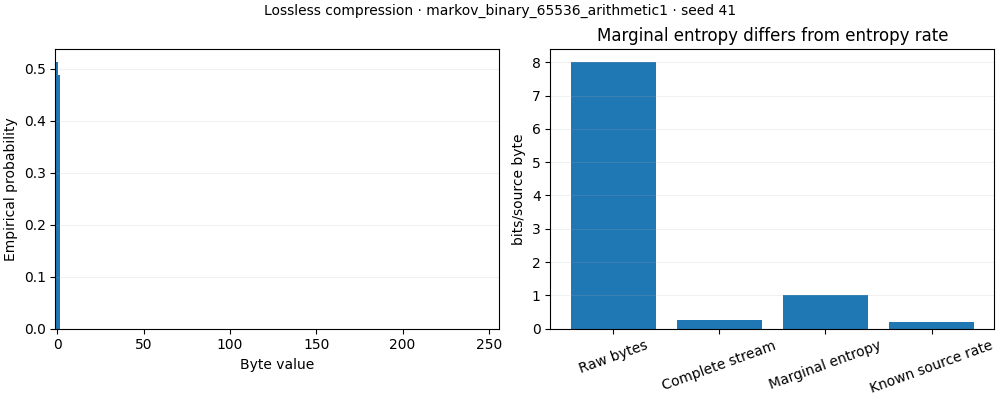

In [4]:
record, path = query("lossless", task="markov_binary", max_bytes=65536, method="arithmetic1")[0]
measured(record)
preview(record)

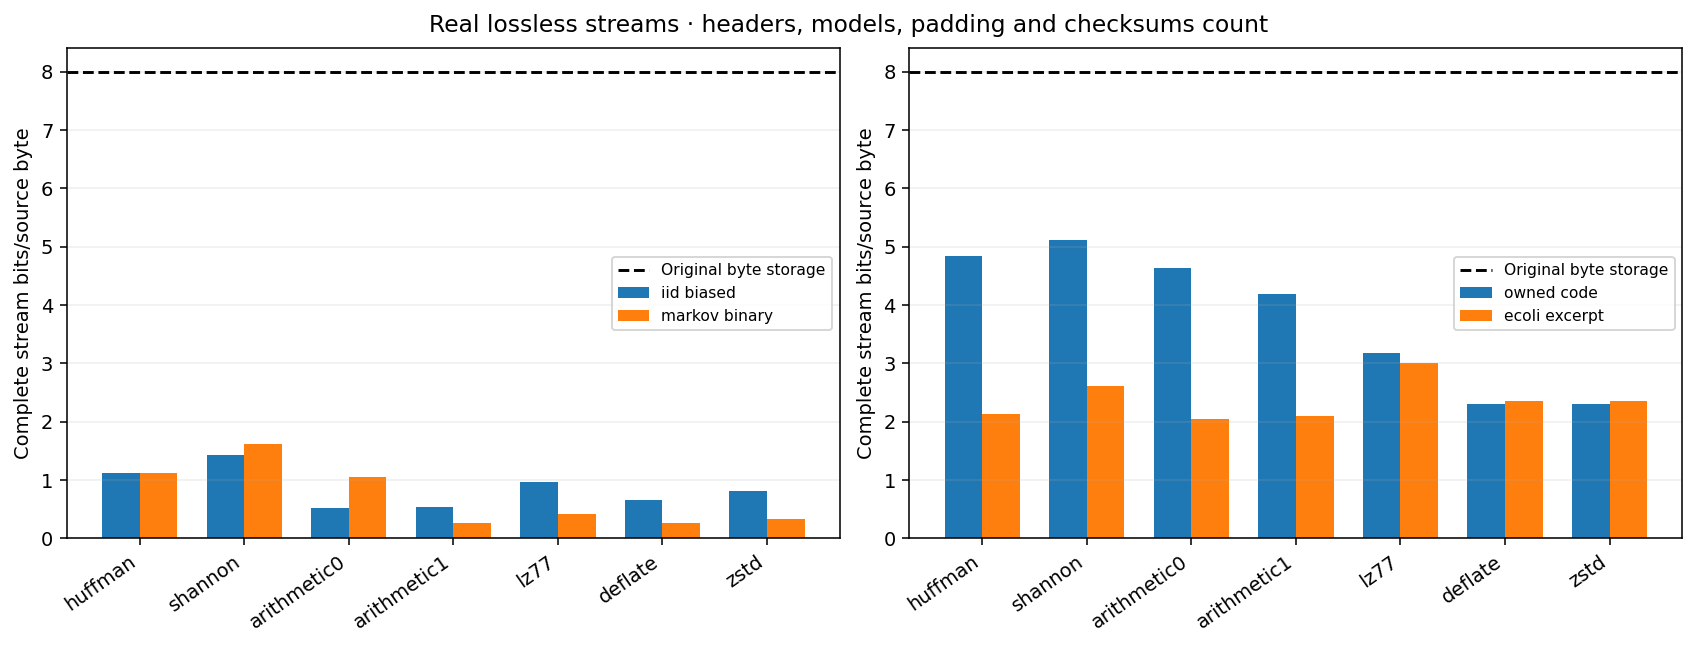

Corpus provenance:
[
  {
    "name": "owned_code",
    "source": "Owner's MIT Sampling & Energy Lab",
    "components": [
      {
        "file": "targets.py",
        "sha256": "3d24644fd0e2aeab3bbe8ec1f854d65e535dae734b4cab2ccfb072d211da93d6"
      },
      {
        "file": "samplers.py",
        "sha256": "584e701370c644875d03b5c8ae85a9569246bb1c648f45e013d8c0cfb8a46722"
      },
      {
        "file": "ebm.py",
        "sha256": "6782d44205da3c99433ea4aec5777d4c66ea6bc3ab33252e981109427854478a"
      },
      {
        "file": "diagnostics.py",
        "sha256": "28afaf39b55256f330f94decf712104df5a7ce6628a834258bec282c14b0afa7"
      },
      {
        "file": "posterior.py",
        "sha256": "05b718c1ba44da302d5b5baac48fdbd4350e3ef90dcbd227c6b0d469441ac8f1"
      }
    ],
    "license": "MIT, see LICENSE",
    "file": "owned_code.txt",
    "bytes": 38192,
    "sha256": "5077857f377ff7ee6087c78d8d54f65bdd73d2ee81cf3e7e1c3b4c45ed47552d"
  },
  {
    "name": "ecoli_excerpt",
    "

In [5]:
display(Image(filename=str(ROOT / "assets/previews/lossless_comparison.png")))
print("Corpus provenance:")
print(json.dumps(json.loads((ROOT / "assets/corpora/manifest.json").read_text()), indent=2))

A dependent Markov source can be compressed below its marginal binary entropy. Real-corpus byte entropy is a descriptive statistic, not a certified source entropy rate. The MIT code and versioned genomic excerpt have explicit origin hashes.